# Sentiment Analysis Project: Comparing SA's systems to analyse book reviews
## NLP for social media exam project (Villa Alessandra Virginia matr. 5405075)

**Objective of this work:**
This notebook performs sentiment analysis on the dataset already preprocessed for sentiment analysis available on Kaggle and linked in the paper. It applies three different methodologies and saves the results of each to a separate CSV file for download.

**Methodologies:**
1.  **VADER** (Lexicon-based) -> Saves to `vader_results.csv`
2.  **BERT** (Supervised Deep Learning) -> Saves to `bert_results.csv`
3.  **Generative AI** (Zero-Shot & Few-Shot with Flan-T5) -> Saves to `genai_results.csv`



In [5]:
# Install necessary libraries
# tqdm is used for progress bars 
!pip install pandas numpy matplotlib seaborn scikit-learn transformers torch vaderSentiment tqdm



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm  # Progress bar

# Set plot style
sns.set_style("whitegrid")



### 1. Data Loading and Preprocessing
We load the full dataset and create the "Ground Truth" by mapping the 1-5 star ratings to categorical labels (Negative/Neutral/Positive).



In [2]:
# Load the dataset
try:
    df = pd.read_csv("Customer_Reviews.csv")
    print(f"Dataset loaded successfully with {len(df)} rows.")
except FileNotFoundError:
    print("Error: 'Customer_Reviews.csv' not found. Please upload the file.")

# Function to map 1-5 stars to Sentiment Labels
def map_rating_to_sentiment(rating):
    if rating <= 2:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Positive'

# Apply mapping (Create Ground Truth)
df['true_sentiment'] = df['rating'].apply(map_rating_to_sentiment)

# Show distribution
print(df['true_sentiment'].value_counts())

# Load dataset
df = pd.read_csv("Customer_Reviews.csv")

# Total word count based on whitespace
total_words = (
    df["reviewText"].astype(str).apply(lambda x: len(x.split())).sum()
)
print(f"Total whitespace tokens/words: {total_words}")



Dataset loaded successfully with 12000 rows.
true_sentiment
Positive    6000
Negative    4000
Neutral     2000
Name: count, dtype: int64
Total whitespace tokens/words: 1310842


### 2. VADER Analysis (Full Dataset)
We apply VADER to all rows and save the results to `vader_results.csv`.



In [10]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def get_vader_sentiment(text):
    if not isinstance(text, str):
        return 'Neutral'
    score = analyzer.polarity_scores(text)['compound']
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

# Create a copy for VADER results
vader_df = df.copy()

print("Running VADER on full dataset...")
# Using tqdm to show progress
tqdm.pandas(desc="VADER Progress")
vader_df['vader_sentiment'] = vader_df['reviewText'].progress_apply(get_vader_sentiment)

# Save results to CSV
vader_output_file = "vader_results.csv"
vader_df.to_csv(vader_output_file, index=False)
print(f"VADER analysis complete. Results saved to '{vader_output_file}'.")



Running VADER on full dataset...


VADER Progress: 100%|███████████████████| 12000/12000 [00:04<00:00, 2475.66it/s]


VADER analysis complete. Results saved to 'vader_results.csv'.


### 3. BERT Analysis (Full Dataset)
We apply the pre-trained BERT model to all rows.
Results are saved to `bert_results.csv`.



In [11]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

# Load model and tokenizer
model_name = "nlptown/bert-base-multilingual-uncased-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

def get_bert_sentiment(text):
    if not isinstance(text, str):
        return 'Neutral'
    
    # Truncate to 512 tokens
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512)
    
    with torch.no_grad():
        outputs = model(**inputs)
    
    predicted_class = torch.argmax(outputs.logits, dim=1).item()
    rating = predicted_class + 1
    return map_rating_to_sentiment(rating)

# Create a copy for BERT results
bert_df = df.copy()

print("Running BERT on full dataset (this may take a while)...")
tqdm.pandas(desc="BERT Progress")
bert_df['bert_sentiment'] = bert_df['reviewText'].progress_apply(get_bert_sentiment)

# Save results to CSV
bert_output_file = "bert_results.csv"
bert_df.to_csv(bert_output_file, index=False)
print(f"BERT analysis complete. Results saved to '{bert_output_file}'.")



Running BERT on full dataset (this may take a while)...


BERT Progress: 100%|██████████████████████| 12000/12000 [53:24<00:00,  3.75it/s]


BERT analysis complete. Results saved to 'bert_results.csv'.


### 4. Generative AI Analysis (Full Dataset)
We run Zero-Shot and Few-Shot prompting on the full dataset using `google/flan-t5-base`.
Results are saved to `genai_results.csv`.



In [12]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Load Generative Model
gen_model_name = "google/flan-t5-base"
gen_tokenizer = AutoTokenizer.from_pretrained(gen_model_name)
gen_model = AutoModelForSeq2SeqLM.from_pretrained(gen_model_name)

def generate_response(prompt):
    inputs = gen_tokenizer(prompt, return_tensors="pt", truncation=True, max_length=512)
    outputs = gen_model.generate(**inputs, max_new_tokens=10)
    return gen_tokenizer.decode(outputs[0], skip_special_tokens=True)

# Define Prompts
def get_zeroshot_sentiment(text):
    prompt = f"Classify the sentiment of this review as Positive, Neutral, or Negative.\nReview: {text}\nSentiment:"
    response = generate_response(prompt).lower()
    if "positive" in response: return "Positive"
    if "negative" in response: return "Negative"
    return "Neutral"

def get_fewshot_sentiment(text):
    prompt = f'''Classify the sentiment:\n\nReview: Terrible book.\nSentiment: Negative\n\nReview: Loved it!\nSentiment: Positive\n\nReview: It was okay.\nSentiment: Neutral\n\nReview: {text}\nSentiment:'''
    response = generate_response(prompt).lower()
    if "positive" in response: return "Positive"
    if "negative" in response: return "Negative"
    return "Neutral"

# Create a copy for GenAI results
genai_df = df.copy()

print("Running Generative AI (Zero-Shot & Few-Shot)...")

# We use a loop with tqdm to process and save periodically if needed, 
# but here we'll process column by column with progress bars.

print("Starting Zero-Shot Analysis...")
tqdm.pandas(desc="Zero-Shot Progress")
genai_df['zeroshot_sentiment'] = genai_df['reviewText'].progress_apply(get_zeroshot_sentiment)

print("Starting Few-Shot Analysis...")
tqdm.pandas(desc="Few-Shot Progress")
genai_df['fewshot_sentiment'] = genai_df['reviewText'].progress_apply(get_fewshot_sentiment)

# Save results to CSV
genai_output_file = "genai_results.csv"
genai_df.to_csv(genai_output_file, index=False)
print(f"Generative AI analysis complete. Results saved to '{genai_output_file}'.")



Running Generative AI (Zero-Shot & Few-Shot)...
Starting Zero-Shot Analysis...


Zero-Shot Progress: 100%|███████████████| 12000/12000 [1:40:31<00:00,  1.99it/s]


Starting Few-Shot Analysis...


Few-Shot Progress: 100%|████████████████| 12000/12000 [1:50:53<00:00,  1.80it/s]

Generative AI analysis complete. Results saved to 'genai_results.csv'.


### 5. Evaluation and Comparison
We load the saved CSV files and generate the final report visualising results through a confusion matrix.



--- VADER Report ---
              precision    recall  f1-score   support

    Negative       0.68      0.41      0.51      4000
     Neutral       0.18      0.02      0.04      2000
    Positive       0.59      0.92      0.72      6000

    accuracy                           0.60     12000
   macro avg       0.49      0.45      0.42     12000
weighted avg       0.55      0.60      0.54     12000



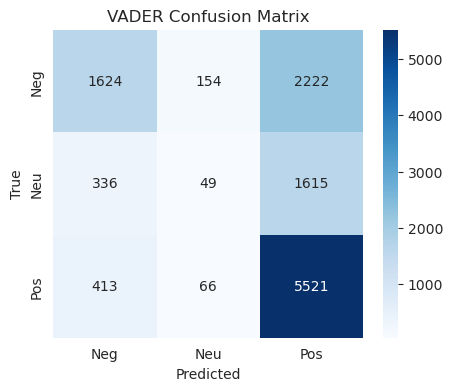

--- BERT Report ---
              precision    recall  f1-score   support

    Negative       0.85      0.79      0.82      4000
     Neutral       0.44      0.53      0.48      2000
    Positive       0.88      0.86      0.87      6000

    accuracy                           0.78     12000
   macro avg       0.72      0.73      0.72     12000
weighted avg       0.80      0.78      0.79     12000



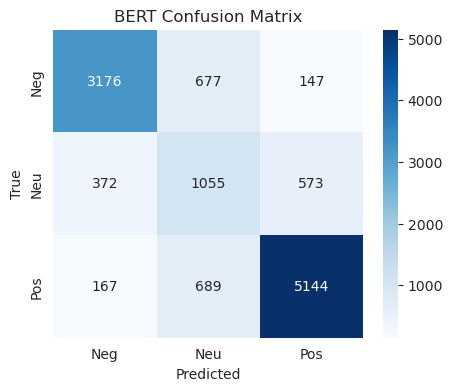

--- Zero-Shot AI Report ---
              precision    recall  f1-score   support

    Negative       0.84      0.89      0.87      4000
     Neutral       0.50      0.00      0.01      2000
    Positive       0.77      0.99      0.86      6000

    accuracy                           0.79     12000
   macro avg       0.70      0.63      0.58     12000
weighted avg       0.75      0.79      0.72     12000



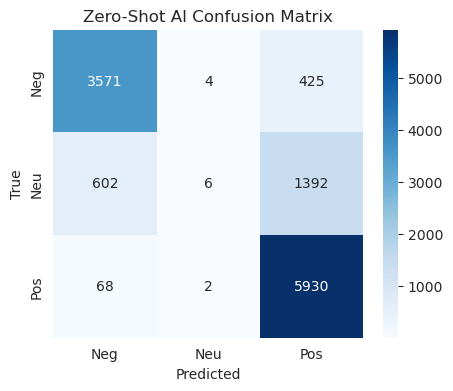

--- Few-Shot AI Report ---
              precision    recall  f1-score   support

    Negative       0.74      0.97      0.84      4000
     Neutral       0.00      0.00      0.00      2000
    Positive       0.84      0.94      0.89      6000

    accuracy                           0.79     12000
   macro avg       0.53      0.64      0.58     12000
weighted avg       0.66      0.79      0.72     12000



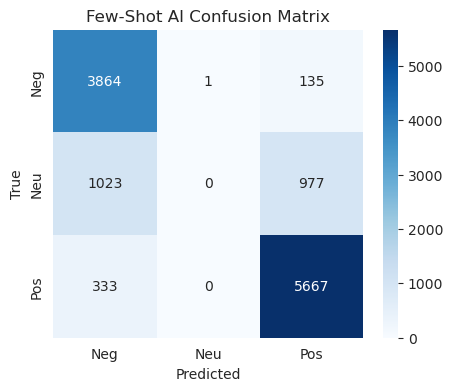

In [13]:
# Load results back 
# Merging logic is simple since row order is preserved
final_df = pd.read_csv("vader_results.csv")
bert_res = pd.read_csv("bert_results.csv")
genai_res = pd.read_csv("genai_results.csv")

final_df['bert_sentiment'] = bert_res['bert_sentiment']
final_df['zeroshot_sentiment'] = genai_res['zeroshot_sentiment']
final_df['fewshot_sentiment'] = genai_res['fewshot_sentiment']

# Helper to plot confusion matrix
def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=['Negative', 'Neutral', 'Positive'])
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Neg', 'Neu', 'Pos'],
                yticklabels=['Neg', 'Neu', 'Pos'])
    plt.title(title)
    plt.ylabel('True')
    plt.xlabel('Predicted')
    plt.show()

# Generate Reports
models = ['vader_sentiment', 'bert_sentiment', 'zeroshot_sentiment', 'fewshot_sentiment']
titles = ['VADER', 'BERT', 'Zero-Shot AI', 'Few-Shot AI']

for model, title in zip(models, titles):
    print(f"--- {title} Report ---")
    print(classification_report(final_df['true_sentiment'], final_df[model]))
    plot_cm(final_df['true_sentiment'], final_df[model], f"{title} Confusion Matrix")

